# §5 Labels and bias audit

A diabetes label is itself a measurement: self-report records a past diagnosis, HbA1c today's glycaemia under
whatever treatment the person receives. This section audits the label and two further bias layers before the
target is frozen (`target-freeze`):

| § | Question |
|---|---|
| 5.1 | How far do self-report and HbA1c agree? |
| 5.2 | Does treatment hide diabetes from HbA1c? |
| 5.3 | What does "undiagnosed" mean? |
| 5.4 | Who is undiagnosed? |
| 5.5 | Does BMI measure adiposity equally for Asian adults? |
| 5.6 | Whom do the 5,730 represent? |
| 5.7 | Is HbA1c missing at random? |
| 5.8 | Does the label pass the decision gate L2 (label revision), and what is frozen? |

All findings here were obtained after looking at the data (`prior_exposure = analysis_seen`); they motivate,
but do not count as, pre-registered tests.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import hashlib
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from scipy import stats
from sklearn.metrics import roc_auc_score

from src import evalkit as E, labels as L, nhanes_io as NIO, survey as S

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
OUT = C.RESULTS_DIR / "S5"
OUT.mkdir(parents=True, exist_ok=True)
WT = C.WEIGHT_PHLEB                      # WTPH2YR: cohort analyses (HbA1c sample)
REG_DATE = "2026-10-11"
RACE = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White", 4: "NH Black", 6: "NH Asian", 7: "Other/multi"}
RES: dict = {}                           # -> results/metrics_S5.json
REG: list[dict] = []                     # -> governance/register/S5.csv


def close(value, target, tol, what):
    """Assert a recomputed number against its verified reference value (independent earlier computation)."""
    assert abs(value - target) <= tol, f"{what}: got {value:.4f}, expected {target} ± {tol}"


def register(dr_id, type_, finding, evidence_ref, evidence_value, decision, alternatives_rejected,
             *, hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""):
    REG.append(dict(dr_id=dr_id, stage="S5", date=REG_DATE, type=type_, finding=finding,
                    evidence_ref=evidence_ref, evidence_value=evidence_value, decision=decision,
                    alternatives_rejected=alternatives_rejected, hyp_id=hyp_id, status=status,
                    check_verdict=check_verdict, check_note=check_note, loop_ref=loop_ref,
                    change_request="", commit=""))


def pct(x, nd=1):
    return f"{100 * x:.{nd}f}%"


NCHS_LABEL = {"present": "meets NCHS standard", "review": "exploratory, NCHS statistical review (df < 8)",
              "suppress": "exploratory, does not meet NCHS standard"}


def nchs_label(r):
    """Presentation label from survey.nchs_status (Parker et al. 2017): present / review / suppress."""
    return NCHS_LABEL[r["nchs_status"]]


def kg_text(r):
    flag = nchs_label(r)
    return (f"{pct(r['est'])} (KG {pct(r['kg_low'])}–{pct(r['kg_high'])}, width {r['ci_width']:.2f}; "
            f"n={r['n']}, events={r['n_events']}, df={r['df']}) -> {flag}")


cohort = NIO.build_cohort()
cohort.attrs = {}   # drop the attached sentinel-audit DataFrame (pandas cannot compare DataFrame attrs in concat)
d = L.add_labels(cohort)
assert len(d) == NIO.COHORT_N == 5730
d["race3"] = d["RIDRETH3"].map(RACE)
print(f"cohort: {len(d):,} adults; columns: {d.shape[1]}")

cohort: 5,730 adults; columns: 81


## 1 Three labels and their agreement

**Why.** Two independent instruments are available: `L_self` (DIQ010 = 1, "a doctor told you that you have diabetes")
and `L_A1c` (HbA1c ≥ 6.5 % at the exam); `L_comb` is their union. Their agreement is measured by Cohen's κ
(unweighted and WTPH2YR-weighted, jackknife df 15), with positive/negative specific agreement because κ depends on
prevalence.

In [2]:
tab = L.confusion(d)
print("Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts")
print(tab, "\n")
unw = L.agreement(d)
jk_agree = S.jackknife(d, L.agreement_vector, weight=WT)
agree = pd.DataFrame({
    "unweighted": [unw[k] for k in L.AGREEMENT_KEYS],
    "weighted": jk_agree["est"], "w_ci_low": jk_agree["ci_low"], "w_ci_high": jk_agree["ci_high"],
}, index=list(L.AGREEMENT_KEYS)).round(3)
print(agree)

L.check_frozen_counts(d)
close(unw["kappa"], 0.699, 0.0015, "kappa unweighted")
close(unw["pa"], 0.739, 0.0015, "PA")
close(unw["na"], 0.959, 0.0015, "NA")
close(unw["sens"], 0.789, 0.0015, "sensitivity of self-report")
close(unw["ppv"], 0.695, 0.0015, "PPV of self-report")
close(jk_agree["est"][0], 0.709, 0.0015, "kappa weighted")
close(jk_agree["ci_low"][0], 0.665, 0.002, "kappa weighted CI low")
close(jk_agree["ci_high"][0], 0.752, 0.002, "kappa weighted CI high")

n_comb = int(d["L_comb"].sum())
miss_self, miss_a1c = int(tab.loc[0, 1]), int(tab.loc[1, 0])
w_prev = S.weighted_prop(d, "L_comb", weight=WT)
print(f"\nL_comb positives {n_comb} ({pct(n_comb / len(d))} unweighted; weighted {kg_text(w_prev)})")
print(f"L_self misses {miss_self}/{n_comb} = {pct(miss_self / n_comb)} of L_comb positives; "
      f"L_A1c misses {miss_a1c}/{n_comb} = {pct(miss_a1c / n_comb)}")
close(w_prev["est"], 0.140, 0.0015, "weighted L_comb prevalence")

label_audit = pd.DataFrame([
    {"label": lab, "positives": int(d[lab].sum()), "prev_unweighted": d[lab].mean(),
     **{f"w_{k}": v for k, v in S.weighted_prop(d, lab, weight=WT).items()
        if k in ("est", "kg_low", "kg_high", "df")}}
    for lab in L.LABEL_COLS])
label_audit.to_csv(OUT / "label_audit.csv", index=False)
agree.to_csv(OUT / "label_agreement.csv")
RES["labels"] = {
    "confusion": {f"self{i}_a1c{j}": int(tab.loc[i, j]) for i in (0, 1) for j in (0, 1)},
    "agreement_unweighted": {k: unw[k] for k in L.AGREEMENT_KEYS},
    "agreement_weighted": {k: {"est": e, "ci_low": lo, "ci_high": hi} for k, e, lo, hi in
                           zip(L.AGREEMENT_KEYS, jk_agree["est"], jk_agree["ci_low"], jk_agree["ci_high"])},
    "positives": {lab: int(d[lab].sum()) for lab in L.LABEL_COLS},
    "L_comb_weighted": {k: w_prev[k] for k in ("est", "ci_low", "ci_high", "kg_low", "kg_high")},
    "L_comb_unweighted": n_comb / len(d),
    "self_missed_share": miss_self / n_comb, "a1c_missed_share": miss_a1c / n_comb,
}
register("DR-S5-02", "label_audit",
         "Self-report and HbA1c are two different instruments with moderate-to-substantial agreement",
         "results/S5/label_agreement.csv; §5.1",
         f"kappa {unw['kappa']:.3f} (weighted {jk_agree['est'][0]:.3f}, CI {jk_agree['ci_low'][0]:.3f}-"
         f"{jk_agree['ci_high'][0]:.3f}); PA {unw['pa']:.3f}; NA {unw['na']:.3f}; sens {unw['sens']:.3f}; PPV {unw['ppv']:.3f}",
         "Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1",
         "Single-instrument label (L_self or L_A1c) as target; kappa alone (prevalence-dependent)",
         check_note="Confusion table, kappa, PA/NA, sens/PPV recomputed and asserted against the verified reference values")

Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts
L_A1c      0    1
L_self           
0       4759  152
1        250  569 

       unweighted  weighted  w_ci_low  w_ci_high
kappa       0.699     0.709     0.665      0.752
pa          0.739     0.741     0.701      0.781
na          0.959     0.968     0.962      0.973
sens        0.789     0.784     0.738      0.830
ppv         0.695     0.703     0.652      0.753

L_comb positives 971 (16.9% unweighted; weighted 14.0% (KG 12.5%–15.7%, width 0.03; n=5730, events=971, df=15) -> meets NCHS standard)
L_self misses 152/971 = 15.7% of L_comb positives; L_A1c misses 250/971 = 25.7%


**So what.** The two instruments agree on 93 % of adults, but agreement *on cases* is much weaker: κ = 0.699
(weighted 0.709, CI 0.665–0.752, only just "substantial" on the Landis & Koch 1977 scale), PA = 0.739 against
NA = 0.959. Self-report detects 78.9 % of HbA1c-positive adults, and only 69.5 % of self-reported diabetics
are HbA1c-positive on the exam day. `L_self` misses 152/971 = 15.7 % of `L_comb` positives and `L_A1c` misses
250/971 = 25.7 %. The disagreement is structured, not noise; §5.2–§5.3 show why.

## 2 Treatment masking

**Why.** 250 self-reported diabetics have HbA1c < 6.5 %. If most of them are treated, a low HbA1c is the
*result* of diagnosis and treatment, and an HbA1c-only label would call well-controlled patients "healthy".
Medication (insulin DIQ050, pills DIQ070) is post-diagnosis information, so it is used here for the audit only,
never as a feature.

self-reported diabetics: 819; HbA1c < 6.5: 250 (30.5%)
  of these on insulin or pills: 165 (66%); untreated: 85, of whom 50 have HbA1c 5.7-6.4
treated self-reported diabetics: 694; HbA1c < 6.5 among them: 23.8%

HbA1c (%) of self-reported diabetics by treatment
                  count  mean   std  min  25%  50%  75%   max
on_med                                                       
insulin or pills  694.0  7.64  1.75  4.1  6.5  7.2  8.3  17.1
no medication     125.0  6.53  1.72  4.7  5.6  6.1  6.7  15.6


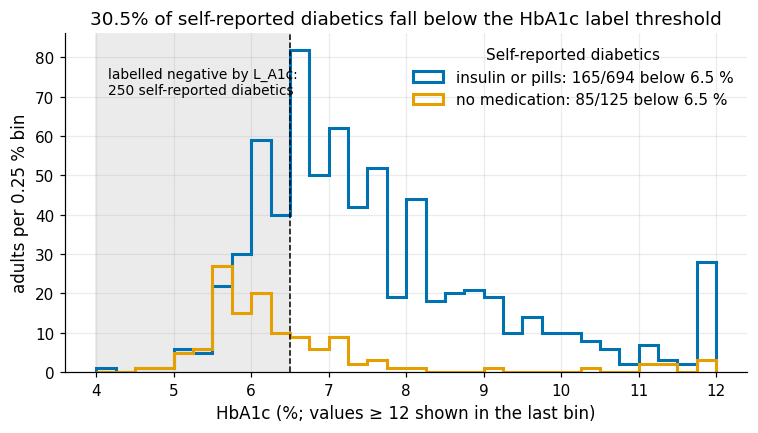

In [3]:
sr = d[d["L_self"] == 1]
ctrl = sr[sr["L_A1c"] == 0]
n_ctrl, n_ctrl_med = len(ctrl), int(ctrl["on_med"].sum())
unmed = ctrl[ctrl["on_med"] == 0]
n_unmed_pre = int(unmed["LBXGH"].between(5.7, 6.49).sum())
on_med = sr[sr["on_med"] == 1]
share_med_below = float((on_med["L_A1c"] == 0).mean())
print(f"self-reported diabetics: {len(sr)}; HbA1c < 6.5: {n_ctrl} ({pct(n_ctrl / len(sr))})")
print(f"  of these on insulin or pills: {n_ctrl_med} ({pct(n_ctrl_med / n_ctrl, 0)}); untreated: {len(unmed)}, "
      f"of whom {n_unmed_pre} have HbA1c 5.7-6.4")
print(f"treated self-reported diabetics: {len(on_med)}; HbA1c < 6.5 among them: {pct(share_med_below)}")
print("\nHbA1c (%) of self-reported diabetics by treatment")
print(sr.groupby(sr["on_med"].map({1: "insulin or pills", 0: "no medication"}))["LBXGH"]
      .describe(percentiles=[.25, .5, .75]).round(2))
assert (n_ctrl, n_ctrl_med, len(unmed), n_unmed_pre, len(on_med)) == (250, 165, 85, 50, 694)
close(n_ctrl / len(sr), 0.305, 0.001, "masking share")
close(share_med_below, 0.238, 0.001, "treated with HbA1c < 6.5")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(4.0, 12.01, 0.25)
ax.axvspan(4.0, C.HBA1C_DIABETES, color="0.92", zorder=0)
for flag, lab, col in [(1, "insulin or pills", plots.PALETTE[4]), (0, "no medication", plots.PALETTE[0])]:
    x = sr.loc[sr["on_med"] == flag, "LBXGH"].clip(upper=11.99)
    below = int((x < C.HBA1C_DIABETES).sum())
    ax.hist(x, bins=bins, histtype="step", lw=2, color=col, label=f"{lab}: {below}/{len(x)} below 6.5 %")
ax.axvline(C.HBA1C_DIABETES, color="k", ls="--", lw=1)
ax.text(4.15, ax.get_ylim()[1] * 0.9, f"labelled negative by L_A1c:\n{n_ctrl} self-reported diabetics", fontsize=9, va="top")
ax.set(xlabel="HbA1c (%; values ≥ 12 shown in the last bin)", ylabel="adults per 0.25 % bin",
       title=f"{pct(n_ctrl / len(sr))} of self-reported diabetics fall below the HbA1c label threshold")
ax.legend(loc="upper right", title="Self-reported diabetics")
plots.savefig(fig, "S5_a1c_by_medication",
              caption=f"HbA1c distribution of the {len(sr)} self-reported diabetics by current insulin/pill use. "
                      f"{n_ctrl} ({pct(n_ctrl / len(sr))}) are below 6.5 %, {n_ctrl_med} of them treated.")
plt.show()

RES["masking"] = {"self_reported": len(sr), "below_6_5": n_ctrl, "below_6_5_share": n_ctrl / len(sr),
                  "below_6_5_on_med": n_ctrl_med, "below_6_5_untreated": len(unmed),
                  "untreated_5_7_to_6_4": n_unmed_pre, "treated": len(on_med),
                  "treated_below_6_5_share": share_med_below}
register("DR-S5-03", "label_bias",
         "Treatment masks diabetes in HbA1c: an HbA1c-only label turns controlled patients into negatives",
         "figures/S5_a1c_by_medication.png; §5.2",
         f"{n_ctrl}/{len(sr)} ({pct(n_ctrl / len(sr))}) self-reported diabetics have HbA1c<6.5; {n_ctrl_med} of them on medication; "
         f"{pct(share_med_below)} of treated patients below 6.5",
         "Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diagnosis)",
         "HbA1c-only target; medication as a feature (leakage by the availability rule)")

**So what.** 250 of 819 self-reported diabetics (30.5 %) are below the HbA1c threshold, and 165 of these
(66 %) take insulin or pills; among all 694 treated patients 23.8 % are "controlled". The remaining 85 are
untreated, 50 of them in the prediabetes range (5.7–6.4 %), consistent with lifestyle-controlled or
early disease. An HbA1c-only label would therefore count successful treatment as absence of disease: this is
the *D_controlled* column of the 3×3 label matrix (§8.6).

## 3 What "undiagnosed" means

**Why.** The 152 adults with HbA1c ≥ 6.5 % who do not report diabetes are the population the screening use case
is about (E-SCREEN). "Undiagnosed" is easily read as "never saw a doctor". DIQ010 = 3 (borderline), DIQ180
(blood test for high blood sugar in the past three years) and DIQ160 (told prediabetes) show whether they
had contact with the system. Counts are unweighted; shares among the undiagnosed are also weighted with
Korn–Graubard intervals.

In [4]:
bl = d["DIQ010"].eq(3)
no = d["DIQ010"].eq(2)
p_bl, p_no = d.loc[bl, "L_A1c"].mean(), d.loc[no, "L_A1c"].mean()
print(f"DIQ010 = 3 (borderline): {int(bl.sum())}; HbA1c >= 6.5: {int(d.loc[bl, 'L_A1c'].sum())} ({pct(p_bl)}) "
      f"vs DIQ010 = 2: {pct(p_no)}")
und_mask = (d["stratum_3x3"] == "Undiagnosed").to_numpy()
und = d[und_mask]
care = {
    "told borderline (DIQ010=3)": und["DIQ010"].eq(3),
    "blood test past 3 years (DIQ180=1)": und["DIQ180"].eq(1),
    "told prediabetes (DIQ160=1)": und["DIQ160"].eq(1),
}
rows = []
for name, s in care.items():
    y = np.where(und_mask, d.index.isin(s[s].index), np.nan)
    w = S.weighted_prop(d, y.astype(float), weight=WT, domain=und_mask)
    rows.append({"contact": name, "n": int(s.sum()), "of": len(und), "share": s.sum() / len(und),
                 "w_est": w["est"], "kg_low": w["kg_low"], "kg_high": w["kg_high"], "df": w["df"],
                 "flags": ";".join(w["nchs_flags"]), "nchs": nchs_label(w)})
care_tab = pd.DataFrame(rows)
print(care_tab.round(3).to_string(index=False))
print(f"DIQ180 missing among undiagnosed: {int(und['DIQ180'].isna().sum())}; DIQ160 missing: {int(und['DIQ160'].isna().sum())} "
      "(borderline respondents skip DIQ160)")
assert int(bl.sum()) == 213 and int(d.loc[bl, "L_A1c"].sum()) == 36 and len(und) == 152
assert care_tab["n"].tolist() == [36, 104, 48]
close(p_bl, 0.169, 0.001, "borderline A1c+ share")
close(p_no, 0.025, 0.001, "DIQ010=2 A1c+ share")
CT = care_tab.set_index("contact")
t180 = CT.loc["blood test past 3 years (DIQ180=1)"]
close(t180["w_est"], 0.625, 0.0015, "DIQ180 weighted share")
print(f"population estimate (WTPH2YR): {pct(t180['w_est'])} of undiagnosed adults had a blood test in the past 3 years "
      f"(KG {pct(t180['kg_low'])}-{pct(t180['kg_high'])}); unweighted sample share {pct(t180['share'])}")
care_tab.to_csv(OUT / "undiagnosed_care_contact.csv", index=False)
RES["undiagnosed_meaning"] = {"borderline_n": int(bl.sum()), "borderline_a1c_pos": int(d.loc[bl, "L_A1c"].sum()),
                              "borderline_a1c_share": p_bl, "no_a1c_share": p_no, "undiagnosed": len(und),
                              "contact": care_tab.set_index("contact")[["n", "share", "w_est", "kg_low", "kg_high"]].to_dict("index")}
register("DR-S5-04", "label_semantics",
         "Most undiagnosed adults had contact with the health system: the gap is diagnosis/communication, not only access",
         "results/S5/undiagnosed_care_contact.csv; §5.3",
         f"undiagnosed adults blood-tested in past 3 y: {pct(t180['w_est'])} weighted (KG {pct(t180['kg_low'])}-{pct(t180['kg_high'])}; "
         f"sample 104/152 = 68%); 36/152 told borderline; 48 told prediabetes",
         "Frame E-SCREEN positives as 'not diagnosed despite contact'; DIQ160/DIQ180 excluded as features (post-test information); borderline kept negative in L_comb and flagged",
         "Describe undiagnosed as 'no access to care'; use DIQ180 as a screening feature")

DIQ010 = 3 (borderline): 213; HbA1c >= 6.5: 36 (16.9%) vs DIQ010 = 2: 2.5%
                           contact   n  of  share  w_est  kg_low  kg_high  df flags                nchs
        told borderline (DIQ010=3)  36 152  0.237  0.235   0.165    0.318  14       meets NCHS standard
blood test past 3 years (DIQ180=1) 104 152  0.684  0.625   0.535    0.709  14       meets NCHS standard
       told prediabetes (DIQ160=1)  48 152  0.316  0.306   0.227    0.395  14       meets NCHS standard
DIQ180 missing among undiagnosed: 2; DIQ160 missing: 37 (borderline respondents skip DIQ160)
population estimate (WTPH2YR): 62.5% of undiagnosed adults had a blood test in the past 3 years (KG 53.5%-70.9%); unweighted sample share 68.4%


**So what.** Borderline respondents are almost seven times as likely to be HbA1c-positive as those answering "no"
(16.9 % vs 2.5 %). An estimated 62.5 % (weighted, WTPH2YR; KG 53.5–70.9 %) of undiagnosed adults had a blood-sugar
test in the past three years (unweighted: 104 of 152 = 68 %); 36 were told they were borderline and 48 that they had
prediabetes. "Undiagnosed" is mostly a diagnosis and communication gap; DIQ160 and DIQ180 record a glucose-test
result and are excluded as features.

## 4 Who is undiagnosed

**Why.** If the undiagnosed share differs by insurance, access or race, `L_self` is a biased label. Domain: adults with
HbA1c ≥ 6.5 % (n = 721); outcome: not self-reported. Proportions get Korn–Graubard intervals and the NCHS flags
(*exploratory* when n or effective n < 30 or the CI is too wide; Parker et al. 2017). The headline is the risk
difference (WTPH2YR, jackknife) on the joint domain's df, with the smaller group's own df as a conservative check.

In [5]:
d["undx"] = 1.0 - d["L_self"]
d["uninsured"] = np.select([d["HIQ011"].eq(2), d["HIQ011"].eq(1)], [1.0, 0.0], np.nan)
d["no_usual_place"] = np.select([d["HUQ030"].eq(2), d["HUQ030"].isin([1, 3])], [1.0, 0.0], np.nan)
a1c_dom = d["L_A1c"].eq(1).to_numpy()


def risk_difference(df, y, ga, gb, weight=WT):
    """Weighted risk difference p(a) - p(b) with JK CI (df = NCHS domain df of a or b)."""
    yv = df[y].to_numpy(float)
    ok = ~np.isnan(yv)
    a, b = np.asarray(ga) & ok, np.asarray(gb) & ok
    y0 = np.nan_to_num(yv)

    def f(_d, w):
        return np.dot(w * a, y0) / np.sum(w * a) - np.dot(w * b, y0) / np.sum(w * b)
    return S.jackknife(df, f, weight=weight, df_override=S.domain_df(df, a | b))


contrasts = [  # (name, column, level a, level b, label a, label b)
    ("uninsured - insured", "uninsured", 1.0, 0.0, "uninsured", "insured"),
    ("no usual place - usual place", "no_usual_place", 1.0, 0.0, "no usual place", "usual place"),
    ("NH Asian - NH White", "RIDRETH3", 6, 3, "NH Asian", "NH White"),
]
prop_rows, rd_rows = [], []
for name, col, a, b, la, lb in contrasts:
    for lev, lab in [(a, la), (b, lb)]:
        r = S.weighted_prop(d, "undx", weight=WT, domain=a1c_dom & d[col].eq(lev).to_numpy())
        prop_rows.append({"group": lab, "contrast": name, **{k: r[k] for k in
                          ("n", "n_events", "est", "kg_low", "kg_high", "ci_width", "n_eff", "df")},
                          "nchs": nchs_label(r), "nchs_status": r["nchs_status"], "flags": ";".join(r["nchs_flags"])})
    rd = risk_difference(d, "undx", a1c_dom & d[col].eq(a).to_numpy(), a1c_dom & d[col].eq(b).to_numpy())
    rd_rows.append({"contrast": name, "rd_pp": 100 * rd["est"], "ci_low_pp": 100 * rd["ci_low"],
                    "ci_high_pp": 100 * rd["ci_high"], "df": rd["df"]})
props = pd.DataFrame(prop_rows).drop_duplicates("group")
rds = pd.DataFrame(rd_rows)
print("Undiagnosed share among HbA1c >= 6.5 (WTPH2YR, Korn-Graubard)")
print(props.drop(columns="flags").round(3).to_string(index=False))
print("\nRisk differences (percentage points, JK CI)")
print(rds.round(1).to_string(index=False))

P = props.set_index("group")
close(P.loc["uninsured", "est"], 0.430, 0.0015, "uninsured share"); assert P.loc["uninsured", "n"] == 49
close(P.loc["uninsured", "kg_low"], 0.242, 0.002, "uninsured KG low"); close(P.loc["uninsured", "kg_high"], 0.635, 0.002, "uninsured KG high")
assert P.loc["uninsured", "df"] == 9 and P.loc["no usual place", "df"] == 9
close(P.loc["insured", "est"], 0.199, 0.0015, "insured share")
close(P.loc["no usual place", "est"], 0.403, 0.0015, "no usual place share"); assert P.loc["no usual place", "n"] == 41
close(P.loc["NH Asian", "est"], 0.362, 0.0015, "Asian share"); assert P.loc["NH Asian", "n"] == 40 and P.loc["NH Asian", "df"] == 4
close(P.loc["NH Asian", "kg_low"], 0.131, 0.002, "Asian KG low"); close(P.loc["NH Asian", "kg_high"], 0.652, 0.002, "Asian KG high")
for g in ("uninsured", "no usual place", "NH Asian"):
    assert P.loc[g, "ci_width"] >= C.NCHS_CI_WIDTH_MAX and P.loc[g, "nchs_status"] == "suppress"
assert P.loc["insured", "nchs"] == "meets NCHS standard"
RD = rds.set_index("contrast")
for name, (e, lo, hi) in {"uninsured - insured": (23.2, 6.2, 40.1), "no usual place - usual place": (19.9, -1.6, 41.5),
                          "NH Asian - NH White": (15.6, -5.7, 36.9)}.items():
    close(RD.loc[name, "rd_pp"], e, 0.06, name); close(RD.loc[name, "ci_low_pp"], lo, 0.06, name + " low")
    close(RD.loc[name, "ci_high_pp"], hi, 0.06, name + " high")

# Degrees of freedom of the contrast. The jackknife uses the domain "group a or group b", which here spans all
# strata (df shown above). The smaller group alone has fewer df (uninsured: 9), so as a conservative check the
# same standard error is combined with the t-quantile of the smaller group's domain df.
rd_df = []
for name, col, a, b, la, lb in contrasts:
    r_ = RD.loc[name]
    se_ = (r_["ci_high_pp"] - r_["ci_low_pp"]) / (2 * stats.t.ppf(0.975, r_["df"]))
    df_min = int(min(P.loc[la, "df"], P.loc[lb, "df"]))
    t_min = stats.t.ppf(0.975, df_min)
    rd_df.append({"contrast": name, "rd_pp": r_["rd_pp"], "df_contrast_domain": int(r_["df"]), "ci_low_pp": r_["ci_low_pp"],
                  "ci_high_pp": r_["ci_high_pp"], "df_smaller_group": df_min,
                  "ci_low_pp_conservative": r_["rd_pp"] - t_min * se_, "ci_high_pp_conservative": r_["rd_pp"] + t_min * se_})
rd_df = pd.DataFrame(rd_df)
display(rd_df.round(1))
RDC = rd_df.set_index("contrast")
assert RDC.loc["uninsured - insured", "df_smaller_group"] == 9
assert RDC.loc["uninsured - insured", "ci_low_pp_conservative"] > 0      # H1a rule holds with either df

Undiagnosed share among HbA1c >= 6.5 (WTPH2YR, Korn-Graubard)


         group                     contrast   n  n_events   est  kg_low  kg_high  ci_width   n_eff  df                                     nchs nchs_status
     uninsured          uninsured - insured  49        18 0.430   0.242    0.635     0.393  33.776   9 exploratory, does not meet NCHS standard    suppress
       insured          uninsured - insured 670       133 0.199   0.157    0.246     0.088 392.084  15                      meets NCHS standard     present
no usual place no usual place - usual place  41        17 0.403   0.200    0.633     0.433  26.951   9 exploratory, does not meet NCHS standard    suppress
   usual place no usual place - usual place 680       135 0.203   0.158    0.256     0.098 327.872  15                      meets NCHS standard     present
      NH Asian          NH Asian - NH White  40        12 0.362   0.131    0.652     0.520  26.575   4 exploratory, does not meet NCHS standard    suppress
      NH White          NH Asian - NH White 362        74 0.206

,contrast,rd_pp,df_contrast_domain,ci_low_pp,ci_high_pp,df_smaller_group,ci_low_pp_conservative,ci_high_pp_conservative
0,uninsured - insured,23.2,15,6.2,40.1,9,5.2,41.1
1,no usual place - usual place,19.9,15,-1.6,41.5,9,-2.9,42.8
2,NH Asian - NH White,15.6,15,-5.7,36.9,4,-12.1,43.4


**Adjusted models.** Each exposure gets **its own** logistic model of "undiagnosed" among HbA1c-positive adults, with
the adjustment set the §4.8 DAG identifies:

| Exposure | Adjustment set (§4.8 DAG) | Not adjusted for, and why |
|---|---|---|
| uninsured | age, sex, SES (PIR + missing-PIR indicator) | usual place of care: a *mediator* (insurance → usual care → diagnosis) |
| no usual place of care | age, sex, SES (PIR + missing-PIR indicator) | insurance: an ancestor whose back-door paths age and SES already close |
| NH Asian (vs NH White) | age, sex | SES and BMI: *mediators* of race |

Each model is fitted unweighted and WTPH2YR-weighted (jackknife); a mutually adjusted model would adjust insurance for
its own mediator.

In [6]:
RACE_LEVELS = ["NH White", *[r for r in RACE.values() if r != "NH White"]]
d["age10"] = d["RIDAGEYR"] / 10
d["male"] = d["RIAGENDR"].eq(1).astype(float)
d["pir"] = d["INDFMPIR"].fillna(d["INDFMPIR"].median())
d["race_cat"] = pd.Categorical(d["race3"], categories=RACE_LEVELS)
ADJ_MODELS = [  # (exposure label, coefficient, formula, adjustment set)
    ("uninsured", "uninsured", "undx ~ uninsured + age10 + male + pir + pir_miss", "age, sex, PIR (+ pir_miss)"),
    ("no usual place", "no_usual_place", "undx ~ no_usual_place + age10 + male + pir + pir_miss", "age, sex, PIR (+ pir_miss)"),
    ("NH Asian", "race_cat[T.NH Asian]", "undx ~ race_cat + age10 + male", "age, sex"),
]


def _wlogit(form, term, mask):
    """stat_fn for survey.jackknife: weighted logit coefficient of `term` on rows with mask & w > 0."""
    def f(df, w):
        m = mask & (w > 0)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit_w = smf.glm(form, data=df[m], family=sm.families.Binomial(), freq_weights=w[m] / w[m].mean()).fit()
        return fit_w.params[term]
    return f


adj_rows = []
for lab, term, form, adj in ADJ_MODELS:
    col = term.split("[")[0]
    cc = a1c_dom & d[[col, "age10", "male", "pir", "pir_miss"]].notna().all(axis=1).to_numpy()
    fit = smf.logit(form, data=d[cc]).fit(disp=0)
    ci = fit.conf_int().loc[term]
    jk = S.jackknife(d, _wlogit(form, term, cc), weight=WT, df_override=S.domain_df(d, cc))
    adj_rows.append({"exposure": lab, "adjustment_set": adj, "n": int(cc.sum()), "events": int(d.loc[cc, "undx"].sum()),
                     "OR": np.exp(fit.params[term]), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                     "OR_w": np.exp(jk["est"]), "w_ci_low": np.exp(jk["ci_low"]), "w_ci_high": np.exp(jk["ci_high"]),
                     "df": jk["df"], "formula": form})
logit_tab = pd.DataFrame(adj_rows)
print(f"domain: {int(a1c_dom.sum())} adults with HbA1c >= 6.5; PIR missing for {int(d.loc[a1c_dom, 'pir_miss'].sum())} "
      f"(indicator); unknown insurance: {int(d.loc[a1c_dom, 'uninsured'].isna().sum())}")
print(logit_tab.drop(columns="formula").round(2).to_string(index=False))
LT = logit_tab.set_index("exposure")
assert LT["n"].tolist() == [719, 721, 721]
excl = lambda lo, hi: lo > 1 or hi < 1   # noqa: E731
LT["unweighted_excludes_1"] = [excl(lo, hi) for lo, hi in zip(LT["ci_low"], LT["ci_high"])]
LT["weighted_excludes_1"] = [excl(lo, hi) for lo, hi in zip(LT["w_ci_low"], LT["w_ci_high"])]
display(LT[["unweighted_excludes_1", "weighted_excludes_1"]])
assert (LT[["OR", "OR_w"]] > 1).all().all()          # every exposure points in the same direction as its crude RD
assert LT.loc["uninsured", "unweighted_excludes_1"] and LT.loc["uninsured", "weighted_excludes_1"]
assert not LT.loc["NH Asian", "unweighted_excludes_1"] and not LT.loc["NH Asian", "weighted_excludes_1"]
assert LT.loc["no usual place", "unweighted_excludes_1"] and not LT.loc["no usual place", "weighted_excludes_1"]  # fits disagree

domain: 721 adults with HbA1c >= 6.5; PIR missing for 93 (indicator); unknown insurance: 2
      exposure             adjustment_set   n  events   OR  ci_low  ci_high  OR_w  w_ci_low  w_ci_high  df
     uninsured age, sex, PIR (+ pir_miss) 719     151 2.22    1.18     4.18  2.90      1.48       5.67  15
no usual place age, sex, PIR (+ pir_miss) 721     152 2.76    1.43     5.33  2.52      0.89       7.09  15
      NH Asian                   age, sex 721     152 1.67    0.81     3.44  2.18      0.84       5.62  15


,unweighted_excludes_1,weighted_excludes_1
exposure,,
uninsured,True,True
no usual place,True,False
NH Asian,False,False


**Reading the models (Table-2 caveat).** Each odds ratio is the estimate for *its own* exposure only. The
coefficients of the adjustment covariates (age, sex, PIR) in the same fits are not effects and are therefore not
shown: they are themselves confounded or partly mediated (Westreich & Greenland 2013, "Table 2 fallacy").
The odds ratios are associations under the assumed DAG, not causal effects of insurance or care.

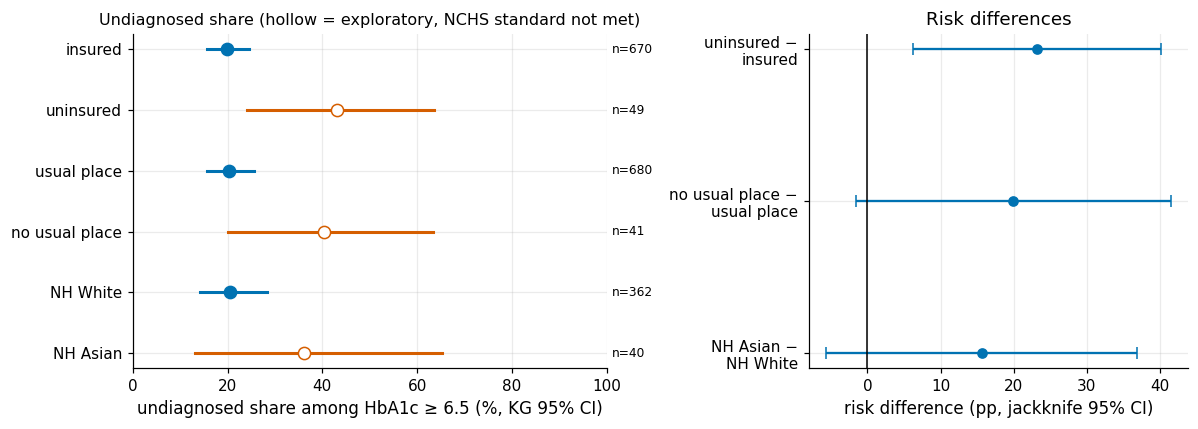

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.25, 1]})
order = ["insured", "uninsured", "usual place", "no usual place", "NH White", "NH Asian"]
pp = P.loc[order]
yy = np.arange(len(order))[::-1]
for yi, (g, r) in zip(yy, pp.iterrows()):
    expl = r["nchs"].startswith("exploratory")
    col = plots.PALETTE[5] if expl else plots.PALETTE[4]
    ax1.plot([r["kg_low"] * 100, r["kg_high"] * 100], [yi, yi], color=col, lw=2)
    ax1.plot(r["est"] * 100, yi, "o", color=col, mfc="white" if expl else col, ms=8)
    ax1.text(101, yi, f"n={int(r['n'])}", va="center", fontsize=8)
ax1.set_yticks(yy, order)
ax1.set(xlim=(0, 100), xlabel="undiagnosed share among HbA1c ≥ 6.5 (%, KG 95% CI)",
        title="Undiagnosed share (hollow = exploratory, NCHS standard not met)")
ax1.title.set_fontsize(10.5)
yr = np.arange(len(rds))[::-1]
ax2.errorbar(rds["rd_pp"], yr, xerr=[rds["rd_pp"] - rds["ci_low_pp"], rds["ci_high_pp"] - rds["rd_pp"]],
             fmt="o", color=plots.PALETTE[4], capsize=4)
ax2.axvline(0, color="k", lw=1)
ax2.set_yticks(yr, [c.replace(" - ", " −\n") for c in rds["contrast"]])
ax2.set(xlabel="risk difference (pp, jackknife 95% CI)", title="Risk differences")
fig.tight_layout()
plots.savefig(fig, "S5_undiagnosed_inequality",
              caption="Share of HbA1c-positive adults who do not report diabetes (WTPH2YR, Korn-Graubard CI) and risk "
                      "differences with delete-one-PSU jackknife CI. Hollow markers: fails the NCHS presentation standard (exploratory).")
plt.show()

props.to_csv(OUT / "undiagnosed_by_group.csv", index=False)
rds.to_csv(OUT / "undiagnosed_risk_differences.csv", index=False)
logit_tab.to_csv(OUT / "undiagnosed_logit.csv", index=False)
RES["undiagnosed_inequality"] = {
    "proportions": props.set_index("group").drop(columns=["contrast"]).to_dict("index"),
    "risk_differences_pp": rds.set_index("contrast").to_dict("index"),
    "adjusted_logit": {r["exposure"]: {k: r[k] for k in ("adjustment_set", "formula", "n", "events", "OR", "ci_low", "ci_high",
                                                          "OR_w", "w_ci_low", "w_ci_high", "df")} for r in adj_rows},
}
register("DR-S5-05", "label_bias",
         "Undiagnosed share is higher without insurance or a usual place of care; small cells do not meet NCHS standards",
         "results/S5/undiagnosed_by_group.csv; results/S5/undiagnosed_risk_differences.csv; figures/S5_undiagnosed_inequality.png",
         f"RD uninsured-insured {RD.loc['uninsured - insured', 'rd_pp']:.1f}pp ({RD.loc['uninsured - insured', 'ci_low_pp']:.1f}, "
         f"{RD.loc['uninsured - insured', 'ci_high_pp']:.1f}); uninsured share 43.0% KG width {P.loc['uninsured', 'ci_width']:.2f}; "
         f"DAG-adjusted OR (age, sex, PIR) uninsured {LT.loc['uninsured', 'OR']:.2f} ({LT.loc['uninsured', 'ci_low']:.2f}, "
         f"{LT.loc['uninsured', 'ci_high']:.2f}), weighted {LT.loc['uninsured', 'OR_w']:.2f} ({LT.loc['uninsured', 'w_ci_low']:.2f}, "
         f"{LT.loc['uninsured', 'w_ci_high']:.2f}); no usual place {LT.loc['no usual place', 'OR']:.2f} ({LT.loc['no usual place', 'ci_low']:.2f}, "
         f"{LT.loc['no usual place', 'ci_high']:.2f}), weighted {LT.loc['no usual place', 'OR_w']:.2f} ({LT.loc['no usual place', 'w_ci_low']:.2f}, "
         f"{LT.loc['no usual place', 'w_ci_high']:.2f})",
         "Headline = risk difference with JK CI (df of the contrast domain; conservative df of the smaller group also shown); proportions with KG CI and NCHS flag; insurance and access are audit/stratification variables only; S8 audits L_self vs L_comb by low_access",
         "Report small-cell proportions as headline; drop small groups; put insurance into the model; one mutually adjusted model "
         "(adjusts insurance for its mediator usual care; Table-2 fallacy)")

**So what.** Among HbA1c-positive adults, 43.0 % of the uninsured but 19.9 % of the insured do not know their
diagnosis: a risk difference of +23.2 pp (6.2, 40.1; df 15), which still excludes zero with the uninsured
group's own df of 9 (table above). For no usual place of care (+19.9 pp, −1.6 to 41.5) and NH Asian vs NH
White (+15.6 pp, −5.7 to 36.9) the intervals include zero; all three group proportions are *exploratory*. In
the DAG-guided models, lacking insurance stays associated with being undiagnosed after age, sex and income
(OR 2.2 unweighted, 2.9 weighted; both CIs exclude 1); for no usual place the fits disagree (weighted OR 2.5,
0.9–7.1). `L_self` thus under-counts disease where access is poorer, hence the union target `L_comb`.

## 5 BMI as a biased measurement of adiposity in Asian adults

**Why.** BMI is the main adiposity feature of any non-laboratory screening model, but Asian adults develop diabetes at
lower BMI (Araneta et al. 2015; WHO Expert Consultation 2004): a possible *feature-level* measurement bias. NH Asian
and NH White adults are compared on the BMI of diabetics, prevalence by BMI band, single-feature AUC of BMI, waist and
waist-to-height ratio (WHtR, paired bootstrap of the gain) and the sensitivity of the BMI ≥ 25 / ≥ 23 cut-offs
(unweighted measurement properties).

In [8]:
grp = {"NH Asian": 6, "NH White": 3}
bmi_dm = []
for g, code in grp.items():
    dm = d[(d["RIDRETH3"] == code) & (d["L_comb"] == 1) & d["BMXBMI"].notna()]
    k = int((dm["BMXBMI"] < 25).sum())
    w = S.weighted_prop(d, (d["BMXBMI"] < 25).astype(float).where(d["BMXBMI"].notna()), weight=WT,
                        domain=((d["RIDRETH3"] == code) & (d["L_comb"] == 1)).to_numpy())
    bmi_dm.append({"group": g, "bmi_lt25": k, "diabetics_with_bmi": len(dm), "share": k / len(dm),
                   "median_bmi": dm["BMXBMI"].median(), "w_share": w["est"], "kg_low": w["kg_low"], "kg_high": w["kg_high"]})
bmi_dm = pd.DataFrame(bmi_dm).set_index("group")
print("BMI < 25 among L_comb diabetics (denominator excludes missing BMI)")
print(bmi_dm.round(3))
assert (bmi_dm.loc["NH Asian", "bmi_lt25"], bmi_dm.loc["NH Asian", "diabetics_with_bmi"]) == (24, 47)
close(bmi_dm.loc["NH Asian", "share"], 0.511, 0.001, "Asian BMI<25"); close(bmi_dm.loc["NH White", "share"], 0.072, 0.001, "White BMI<25")

BANDS = [0, 23, 25, 30, 200]
BLAB = ["<23", "23–24.9", "25–29.9", "≥30"]
d["bmi_band"] = pd.cut(d["BMXBMI"], BANDS, right=False, labels=BLAB)
band_rows = []
for g, code in grp.items():
    for b in BLAB:
        m = ((d["RIDRETH3"] == code) & (d["bmi_band"] == b)).to_numpy()
        w = S.weighted_prop(d, "L_comb", weight=WT, domain=m)
        band_rows.append({"group": g, "bmi_band": b, "n": int(m.sum()), "cases": int(d.loc[m, "L_comb"].sum()),
                          "prev": d.loc[m, "L_comb"].mean(), "w_prev": w["est"], "kg_low": w["kg_low"],
                          "kg_high": w["kg_high"], "ci_width": w["ci_width"], "df": w["df"],
                          "nchs_status": w["nchs_status"], "flags": ";".join(w["nchs_flags"])})
bands = pd.DataFrame(band_rows)
print("\nL_comb prevalence by BMI band (unweighted and WTPH2YR with KG CI)")
print(bands.round(3).to_string(index=False))
B_ = bands.set_index(["group", "bmi_band"])
n_flag_asian = int((bands.loc[bands["group"] == "NH Asian", "nchs_status"] != "present").sum())
print(f"NH Asian BMI bands failing the NCHS presentation standard: {n_flag_asian} of {len(BLAB)}")
assert n_flag_asian >= 3
close(B_.loc[("NH Asian", "<23"), "prev"], 0.121, 0.001, "Asian <23"); close(B_.loc[("NH White", "<23"), "prev"], 0.043, 0.001, "White <23")
close(B_.loc[("NH Asian", "23–24.9"), "prev"], 0.175, 0.001, "Asian 23-25"); close(B_.loc[("NH White", "23–24.9"), "prev"], 0.033, 0.001, "White 23-25")
close(B_.loc[("NH Asian", "25–29.9"), "prev"], 0.115, 0.001, "Asian 25-30"); close(B_.loc[("NH Asian", "25–29.9"), "w_prev"], 0.053, 0.001, "Asian 25-30 weighted")
close(B_.loc[("NH Asian", "<23"), "w_prev"], 0.078, 0.001, "Asian <23 weighted"); close(B_.loc[("NH Asian", "23–24.9"), "w_prev"], 0.140, 0.001, "Asian 23-25 weighted")

BMI < 25 among L_comb diabetics (denominator excludes missing BMI)
          bmi_lt25  diabetics_with_bmi  share  median_bmi  w_share  kg_low  kg_high
group                                                                              
NH Asian        24                  47  0.511        24.9    0.501   0.255    0.747
NH White        35                 488  0.072        32.7    0.067   0.045    0.096

L_comb prevalence by BMI band (unweighted and WTPH2YR with KG CI)
   group bmi_band    n  cases  prev  w_prev  kg_low  kg_high  ci_width  df nchs_status                  flags
NH Asian      <23  107     13 0.121   0.078   0.028    0.167     0.139   9    suppress      rel_ci_width>130%
NH Asian  23–24.9   63     11 0.175   0.140   0.049    0.291     0.242   5    suppress rel_ci_width>130%;df<8
NH Asian  25–29.9   96     11 0.115   0.053   0.014    0.133     0.119   8    suppress      rel_ci_width>130%
NH Asian      ≥30   44     12 0.273   0.284   0.104    0.536     0.431   5    suppress    

In [9]:
FEATS = {"BMI": "BMXBMI", "waist": "BMXWAIST", "WHtR": "whtr"}
B = C.N_BOOT
rng = np.random.default_rng(E.derive_seed(C.SEED_MASTER, "S5", "auc_bootstrap"))


def auc_set(g):
    out = {}
    for f, col in FEATS.items():
        ok = g[col].notna()
        out[f] = roc_auc_score(g.loc[ok, "L_comb"], g.loc[ok, col])
    both = g["BMXBMI"].notna() & g["whtr"].notna()
    out["gain"] = (roc_auc_score(g.loc[both, "L_comb"], g.loc[both, "whtr"])
                   - roc_auc_score(g.loc[both, "L_comb"], g.loc[both, "BMXBMI"]))
    return out


roc_rows, boot_store = [], {}
for g, code in grp.items():
    sub = d.loc[d["RIDRETH3"] == code, ["L_comb", *FEATS.values()]].reset_index(drop=True)
    est = auc_set(sub)
    pos, neg = np.flatnonzero(sub["L_comb"] == 1), np.flatnonzero(sub["L_comb"] == 0)
    reps = pd.DataFrame([auc_set(sub.iloc[np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])])
                         for _ in range(B)])
    boot_store[g] = reps
    for k in [*FEATS, "gain"]:
        roc_rows.append({"group": g, "measure": k if k != "gain" else "WHtR − BMI (paired)",
                         "n": int(sub[FEATS[k]].notna().sum()) if k in FEATS else int((sub["BMXBMI"].notna() & sub["whtr"].notna()).sum()),
                         "auc": est[k], "ci_low": reps[k].quantile(0.025), "ci_high": reps[k].quantile(0.975)})
roc = pd.DataFrame(roc_rows)
gain_diff = boot_store["NH Asian"]["gain"] - boot_store["NH White"]["gain"]
print(f"Single-feature ROC-AUC for L_comb (stratified bootstrap, B = {B})")
print(roc.round(3).to_string(index=False))
print(f"Asian minus White WHtR gain: {roc.iloc[3]['auc'] - roc.iloc[7]['auc']:+.3f} "
      f"(bootstrap 95% CI {gain_diff.quantile(.025):+.3f}, {gain_diff.quantile(.975):+.3f})")
RO = roc.set_index(["group", "measure"])
assert gain_diff.quantile(.025) > 0, "Asian WHtR gain no longer exceeds the White gain"
close(RO.loc[("NH Asian", "BMI"), "auc"], 0.573, 0.001, "Asian BMI AUC")
close(RO.loc[("NH Asian", "waist"), "auc"], 0.697, 0.001, "Asian waist AUC")
close(RO.loc[("NH Asian", "WHtR"), "auc"], 0.714, 0.001, "Asian WHtR AUC")
close(RO.loc[("NH White", "BMI"), "auc"], 0.701, 0.001, "White BMI AUC")
close(RO.loc[("NH White", "WHtR"), "auc"], 0.749, 0.001, "White WHtR AUC")
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"], 0.137, 0.0006, "Asian gain")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"], 0.049, 0.0006, "White gain")
tol_ci = 0.002 if C.IS_FINAL else 0.03   # bootstrap CI bounds: FINAL (B=1000) reproduces 0.093-0.181 / 0.039-0.058
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "ci_low"], 0.093, tol_ci, "Asian gain CI low")
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "ci_high"], 0.181, tol_ci, "Asian gain CI high")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "ci_low"], 0.039, tol_ci, "White gain CI low")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "ci_high"], 0.058, tol_ci, "White gain CI high")

Single-feature ROC-AUC for L_comb (stratified bootstrap, B = 1000)
   group             measure    n   auc  ci_low  ci_high
NH Asian                 BMI  310 0.573   0.486    0.663
NH Asian               waist  296 0.697   0.618    0.770
NH Asian                WHtR  296 0.714   0.640    0.793
NH Asian WHtR − BMI (paired)  296 0.137   0.093    0.181
NH White                 BMI 3370 0.701   0.677    0.724
NH White               waist 3274 0.751   0.729    0.772
NH White                WHtR 3268 0.749   0.727    0.770
NH White WHtR − BMI (paired) 3264 0.049   0.039    0.058
Asian minus White WHtR gain: +0.088 (bootstrap 95% CI +0.044, +0.135)


**Design-aware interval for the gain difference.** The bootstrap above resamples *people*, but NHANES adults are
clustered in 30 PSUs; people in the same PSU share neighbourhood, field team and exam period, so person-level
resampling can understate the uncertainty. As a check, the Asian − White difference in WHtR gain is also
bootstrapped at the PSU level (Rao–Wu rescaled bootstrap within the 15 strata, `survey.rao_wu_weights`; the
replicate multiplicities enter the unweighted AUCs as frequency weights).

In [10]:
diff_est = float(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"] - RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"])
MULT = S.rao_wu_weights(d, np.ones(len(d)), B, seed=E.derive_seed(C.SEED_MASTER, "S5", "psu_bootstrap"))
both_ok = (d["BMXBMI"].notna() & d["whtr"].notna()).to_numpy()


def _gain_w(mask, w):
    m = mask & both_ok & (w > 0)
    y = d["L_comb"].to_numpy()[m]
    return (roc_auc_score(y, d["whtr"].to_numpy()[m], sample_weight=w[m])
            - roc_auc_score(y, d["BMXBMI"].to_numpy()[m], sample_weight=w[m]))


is_as, is_wh = d["RIDRETH3"].eq(6).to_numpy(), d["RIDRETH3"].eq(3).to_numpy()
psu_diff = np.array([_gain_w(is_as, MULT[:, b]) - _gain_w(is_wh, MULT[:, b]) for b in range(B)])
gain_ci = pd.DataFrame([
    {"method": "person-level stratified bootstrap", "est": diff_est,
     "ci_low": gain_diff.quantile(.025), "ci_high": gain_diff.quantile(.975), "se": gain_diff.std()},
    {"method": "PSU cluster bootstrap (Rao-Wu)", "est": diff_est,
     "ci_low": np.quantile(psu_diff, .025), "ci_high": np.quantile(psu_diff, .975), "se": psu_diff.std()},
])
print(f"Asian − White difference in paired WHtR − BMI gain (B = {B})")
print(gain_ci.round(3).to_string(index=False))
close(diff_est, 0.088, 0.0006, "gain difference")
assert np.quantile(psu_diff, .025) > 0, "PSU bootstrap CI of the gain difference includes 0"
if C.IS_FINAL:   # reviewer's independent PSU bootstrap: 0.039-0.116
    close(np.quantile(psu_diff, .025), 0.039, 0.01, "PSU CI low"); close(np.quantile(psu_diff, .975), 0.116, 0.01, "PSU CI high")
gain_ci.to_csv(OUT / "whtr_gain_difference_ci.csv", index=False)

Asian − White difference in paired WHtR − BMI gain (B = 1000)
                           method   est  ci_low  ci_high    se
person-level stratified bootstrap 0.088   0.044    0.135 0.023
   PSU cluster bootstrap (Rao-Wu) 0.088   0.035    0.116 0.021


**So what.** Clustering does not inflate the uncertainty here (FINAL run, B = 1,000: SE 0.021 at PSU level vs
0.023 at person level), but the PSU-level interval is shifted towards zero (0.035–0.116 vs 0.044–0.135). It
still excludes zero, so the larger WHtR gain in Asian adults is not an artefact of ignoring the survey's
clustering. The design-aware (PSU) interval is the one quoted from here on; with 30 PSUs and only 15 strata it
is itself approximate.

In [11]:
cut_rows = []
for g, code in grp.items():
    sub = d[(d["RIDRETH3"] == code) & d["BMXBMI"].notna()]
    y = sub["L_comb"].eq(1)
    for cut in (25, 23):
        flag = sub["BMXBMI"] >= cut
        cut_rows.append({"group": g, "rule": f"BMI ≥ {cut}", "sensitivity": flag[y].mean(),
                         "specificity": (~flag[~y]).mean(), "flagged_share": flag.mean(), "cases": int(y.sum())})
cuts = pd.DataFrame(cut_rows)
print(cuts.round(3).to_string(index=False))
CU = cuts.set_index(["group", "rule"])
close(CU.loc[("NH Asian", "BMI ≥ 25"), "sensitivity"], 0.489, 0.001, "Asian sens BMI>=25")
close(CU.loc[("NH White", "BMI ≥ 25"), "sensitivity"], 0.928, 0.001, "White sens BMI>=25")
close(CU.loc[("NH Asian", "BMI ≥ 23"), "sensitivity"], 0.723, 0.001, "Asian sens BMI>=23")
close(CU.loc[("NH Asian", "BMI ≥ 23"), "specificity"], 0.357, 0.001, "Asian spec BMI>=23")

   group     rule  sensitivity  specificity  flagged_share  cases
NH Asian BMI ≥ 25        0.489        0.555          0.452     47
NH Asian BMI ≥ 23        0.723        0.357          0.655     47
NH White BMI ≥ 25        0.928        0.303          0.731    488
NH White BMI ≥ 23        0.957        0.161          0.856    488


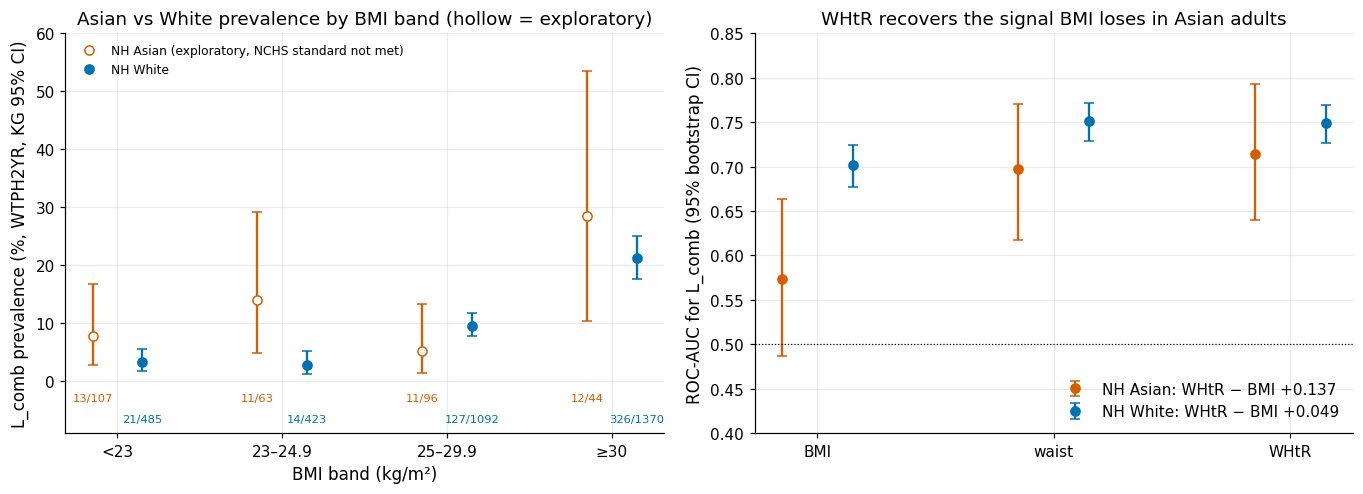

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
xb = np.arange(len(BLAB))
for i, (g, col) in enumerate([("NH Asian", plots.PALETTE[5]), ("NH White", plots.PALETTE[4])]):
    sb = bands[bands["group"] == g]
    off = (i - 0.5) * 0.3
    ax1.errorbar(xb + off, sb["w_prev"] * 100, yerr=[(sb["w_prev"] - sb["kg_low"]) * 100, (sb["kg_high"] - sb["w_prev"]) * 100],
                 fmt="none", ecolor=col, capsize=3)
    ok = (sb["nchs_status"] == "present").to_numpy()
    ax1.plot((xb + off)[ok], sb["w_prev"].to_numpy()[ok] * 100, "o", color=col, label=g if ok.any() else None)
    ax1.plot((xb + off)[~ok], sb["w_prev"].to_numpy()[~ok] * 100, "o", color=col, mfc="white",
             label=f"{g} (exploratory, NCHS standard not met)" if (~ok).any() else None)
    for x_, (_, r) in zip(xb + off, sb.iterrows()):
        ax1.text(x_, -3.5 - 3.5 * i, f"{r['cases']}/{r['n']}", ha="center", fontsize=7.5, color=col)
ax1.set_xticks(xb, BLAB)
ax1.set(xlabel="BMI band (kg/m²)", ylabel="L_comb prevalence (%, WTPH2YR, KG 95% CI)", ylim=(-9, 60),
        title="Asian vs White prevalence by BMI band (hollow = exploratory)")
ax1.legend(loc="upper left", fontsize=8)
meas = ["BMI", "waist", "WHtR"]
for i, (g, col) in enumerate([("NH Asian", plots.PALETTE[5]), ("NH White", plots.PALETTE[4])]):
    rr = RO.loc[g].loc[meas]
    off = (i - 0.5) * 0.3
    ax2.errorbar(np.arange(3) + off, rr["auc"], yerr=[rr["auc"] - rr["ci_low"], rr["ci_high"] - rr["auc"]],
                 fmt="o", color=col, capsize=3,
                 label=f"{g}: WHtR − BMI {RO.loc[(g, 'WHtR − BMI (paired)'), 'auc']:+.3f}")
ax2.axhline(0.5, color="k", lw=0.8, ls=":")
ax2.set_xticks(range(3), meas)
ax2.set(ylabel="ROC-AUC for L_comb (95% bootstrap CI)", ylim=(0.4, 0.85),
        title="WHtR recovers the signal BMI loses in Asian adults")
ax2.legend(loc="lower right")
fig.tight_layout()
plots.savefig(fig, "S5_asian_bmi_whtr",
              caption="Left: L_comb prevalence by BMI band, NH Asian vs NH White (WTPH2YR, Korn-Graubard CI; labels = cases/n; "
                      "hollow markers fail the NCHS presentation standard and are exploratory). "
                      "Right: single-feature ROC-AUC of BMI, waist and WHtR with stratified bootstrap CI; legend = paired WHtR - BMI gain.")
plt.show()

roc.to_csv(OUT / "bmi_race_roc.csv", index=False)
bands.to_csv(OUT / "bmi_band_prevalence.csv", index=False)
cuts.to_csv(OUT / "bmi_cutoff_sensitivity.csv", index=False)
RES["asian_bmi"] = {
    "bmi_lt25_among_diabetics": bmi_dm.to_dict("index"),
    "band_prevalence": {f"{g}|{b}": v for (g, b), v in B_[["n", "cases", "prev", "w_prev", "kg_low", "kg_high"]].to_dict("index").items()},
    "auc": {f"{g}|{m}": v for (g, m), v in RO[["n", "auc", "ci_low", "ci_high"]].to_dict("index").items()},
    "gain_difference_asian_minus_white": {"est": float(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"] - RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"]),
                                          "ci_low": gain_diff.quantile(.025), "ci_high": gain_diff.quantile(.975),
                                          "psu_ci_low": np.quantile(psu_diff, .025), "psu_ci_high": np.quantile(psu_diff, .975),
                                          "psu_se": psu_diff.std(), "person_se": gain_diff.std()},
    "cutoffs": {f"{g}|{r}": v for (g, r), v in CU.to_dict("index").items()},
    "n_boot": B,
}
register("DR-S5-06", "measurement_bias",
         "BMI under-measures diabetes-relevant adiposity in NH Asian adults; WHtR recovers discrimination",
         "results/S5/bmi_race_roc.csv; results/S5/bmi_band_prevalence.csv; figures/S5_asian_bmi_whtr.png",
         f"BMI<25 among diabetics: Asian 24/47 (51.1%) vs White {pct(bmi_dm.loc['NH White', 'share'])}; AUC gain WHtR-BMI Asian "
         f"{RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'auc']:+.3f} ({RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'ci_low']:.3f}, "
         f"{RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'ci_high']:.3f}) vs White {RO.loc[('NH White', 'WHtR − BMI (paired)'), 'auc']:+.3f}",
         "Pre-register P14 (WHtR replaces waist, BMI kept) as S8 mitigation arm with White control; Asian results exploratory (40 A1c-positive cases); no group-specific thresholds",
         "Race-specific BMI cut-offs in the model; adding WHtR on top of waist (redundant); race x BMI interaction (not detectable, §4.12)",
         hyp_id="H-P14")

**So what.** Half of the Asian diabetics (24/47, 51.1 %) have a "normal" BMI below 25, against 7.2 % of White
diabetics (the BMI-band prevalences rest on 44–107 Asian adults each and are exploratory). BMI barely
discriminates in Asian adults (AUC 0.573), while waist (0.697) and WHtR (0.714) do.
The paired WHtR − BMI gain is +0.137 in Asian against +0.049 in White adults; the difference, +0.088, excludes
zero with person-level and PSU-level resampling (PSU 0.035–0.116, FINAL). A BMI ≥ 25 rule finds 48.9 % of Asian
cases (White 92.8 %); the ADA cut-off of 23 for Asian Americans raises this to 72.3 % at a specificity of 35.7 %.
With 40–50 Asian cases this is a measurement *signal* (consistent with Araneta et al. 2015) that motivates the
pre-registered WHtR arm P14 (§8.9).

## 6 Representation and response

**Why.** The composition, response rates and Kish design effect are those of §1.10; the new check here is whether exam
participation relates to health (self-reported diabetes, WTINT2YR, interview-only vs adults with an HbA1c result).

dimension            level    n  sample_share  weighted_share  diff_pp
      age            20-39 1414         0.247           0.348  -10.161
      age            40-59 1671         0.292           0.338   -4.632
      age              60+ 2645         0.462           0.314   14.794
     race Mexican American  386         0.067           0.071   -0.361
     race         NH Asian  315         0.055           0.061   -0.621
     race         NH Black  676         0.118           0.110    0.791
     race         NH White 3408         0.595           0.602   -0.731
     race   Other Hispanic  582         0.102           0.096    0.601
     race      Other/multi  363         0.063           0.060    0.320

Kish design effect of WTPH2YR: 1.55 (effective n ≈ 3,707); L_comb unweighted 16.9% vs weighted 14.0%
§4.4: age structure explains 84% of the 2.9 pp unweighted-weighted gap
documented response rates: interview 34.6%, exam 25.7%


self-reported diabetes (WTINT2YR): interview-only adults 8.8% (KG 7.0%–10.9%, width 0.04; n=1742, events=202, df=15) -> meets NCHS standard
                                   adults with HbA1c   11.7% (KG 10.2%–13.4%, width 0.03; n=5767, events=819, df=15) -> meets NCHS standard
difference with HbA1c - interview-only: +2.9 pp (1.0, 4.8)


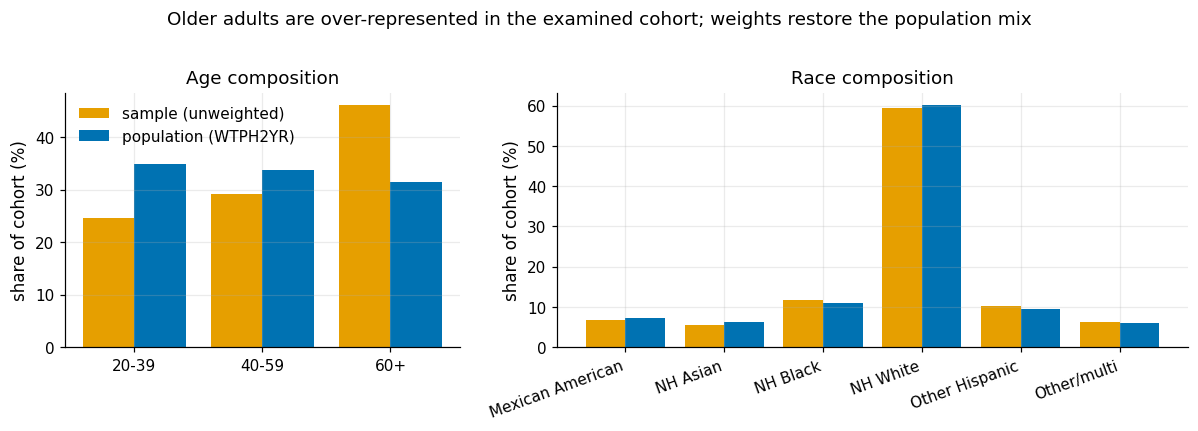

In [13]:
band_s = S.age_band(d["RIDAGEYR"]).to_numpy()
rep_rows = []
for dim, vals in [("age", band_s), ("race", d["race3"].to_numpy())]:
    for lev in pd.unique(vals):
        m = vals == lev
        rep_rows.append({"dimension": dim, "level": lev, "n": int(m.sum()), "sample_share": m.mean(),
                         "weighted_share": d.loc[m, WT].sum() / d[WT].sum()})
rep = pd.DataFrame(rep_rows).sort_values(["dimension", "level"]).reset_index(drop=True)
rep["diff_pp"] = 100 * (rep["sample_share"] - rep["weighted_share"])
print(rep.round(3).to_string(index=False))
deff = S.kish_deff(d[WT])
unw_prev = d["L_comb"].mean()
print(f"\nKish design effect of WTPH2YR: {deff:.2f} (effective n ≈ {len(d) / deff:,.0f}); "
      f"L_comb unweighted {pct(unw_prev)} vs weighted {pct(w_prev['est'])}")
RP = rep.set_index(["dimension", "level"])
close(RP.loc[("age", "60+"), "sample_share"], 0.462, 0.001, "60+ sample"); close(RP.loc[("age", "60+"), "weighted_share"], 0.314, 0.001, "60+ weighted")
close(RP.loc[("age", "20-39"), "sample_share"], 0.247, 0.001, "20-39 sample"); close(RP.loc[("age", "20-39"), "weighted_share"], 0.348, 0.001, "20-39 weighted")
close(deff, 1.55, 0.01, "Kish deff")
age_explained = R.load_section("S4")["prevalence"]["gap_explained_by_age"]   # S4: sample rates re-weighted to the population age mix
print(f"§4.4: age structure explains {100 * age_explained:.0f}% of the {100 * (unw_prev - w_prev['est']):.1f} pp unweighted-weighted gap")
close(age_explained, 0.84, 0.01, "share of gap explained by age (S4)")

# Response rates are documented by NCHS, not derivable from public files (§1.10; NHANES 2021-2023
# overview brief, https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/overviewbrief.aspx?Cycle=2021-2023).
RESPONSE = {"interview_unweighted": 0.346, "exam_unweighted": 0.257}
print(f"documented response rates: interview {pct(RESPONSE['interview_unweighted'])}, exam {pct(RESPONSE['exam_unweighted'])}")

merged = NIO.load_merged()
merged.attrs = {}
# Domains are masks on the full 11,933-row design (weights zeroed outside), never row subsets, so every
# jackknife replicate keeps all strata and PSUs.
merged["self_dm"] = merged["DIQ010"].eq(1).astype(float).where(merged["DIQ010"].notna())
adult = (merged["RIDAGEYR"] >= C.ADULT_MIN_AGE).to_numpy()
io_mask = adult & merged["RIDSTATR"].eq(1).to_numpy()
a1c_mask = adult & (merged["RIDSTATR"].eq(2) & merged["LBXGH"].notna()).to_numpy()
p_io = S.weighted_prop(merged, "self_dm", weight=C.WEIGHT_INTERVIEW, domain=io_mask)
p_a1c = S.weighted_prop(merged, "self_dm", weight=C.WEIGHT_INTERVIEW, domain=a1c_mask)
rd_sel = risk_difference(merged, "self_dm", a1c_mask, io_mask, weight=C.WEIGHT_INTERVIEW)
print(f"self-reported diabetes (WTINT2YR): interview-only adults {kg_text(p_io)}")
print(f"                                   adults with HbA1c   {kg_text(p_a1c)}")
print(f"difference with HbA1c - interview-only: {100 * rd_sel['est']:+.1f} pp ({100 * rd_sel['ci_low']:.1f}, {100 * rd_sel['ci_high']:.1f})")
close(p_io["est"], 0.088, 0.0015, "interview-only self-report"); close(p_a1c["est"], 0.117, 0.0015, "with-A1c self-report")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, dim in zip(axes, ["age", "race"]):
    rr = rep[rep["dimension"] == dim]
    x = np.arange(len(rr))
    ax.bar(x - 0.2, rr["sample_share"] * 100, 0.4, label="sample (unweighted)", color=plots.PALETTE[0])
    ax.bar(x + 0.2, rr["weighted_share"] * 100, 0.4, label="population (WTPH2YR)", color=plots.PALETTE[4])
    ax.set_xticks(x, rr["level"], rotation=0 if dim == "age" else 20, ha="center" if dim == "age" else "right")
    ax.set(ylabel="share of cohort (%)", title=f"{dim.capitalize()} composition")
axes[0].legend()
fig.suptitle("Older adults are over-represented in the examined cohort; weights restore the population mix", y=1.02)
fig.tight_layout()
plots.savefig(fig, "S5_representation",
              caption="Sample versus WTPH2YR-weighted composition of the 5,730-adult cohort by age band and race/ethnicity.")
plt.show()

rep.to_csv(OUT / "representation.csv", index=False)
RES["representation"] = {
    "shares": {f"{a}|{b}": v for (a, b), v in RP[["n", "sample_share", "weighted_share"]].to_dict("index").items()},
    "kish_deff": deff, "n_eff_kish": len(d) / deff, "L_comb_unweighted": unw_prev,
    "response_rates_documented": RESPONSE,
    "self_dm_interview_only": {k: p_io[k] for k in ("est", "kg_low", "kg_high", "n")},
    "self_dm_with_a1c": {k: p_a1c[k] for k in ("est", "kg_low", "kg_high", "n")},
    "selection_rd": {"est": rd_sel["est"], "ci_low": rd_sel["ci_low"], "ci_high": rd_sel["ci_high"]},
}
register("DR-S5-07", "representation",
         "Cohort over-represents older adults; exam participants report more diabetes than interview-only adults",
         "results/S5/representation.csv; figures/S5_representation.png",
         f"60+: sample {pct(RP.loc[('age', '60+'), 'sample_share'])} vs weighted {pct(RP.loc[('age', '60+'), 'weighted_share'])}; "
         f"Kish deff {deff:.2f}; self-report interview-only {pct(p_io['est'])} vs with HbA1c {pct(p_a1c['est'])}; response 34.6%/25.7%",
         "Descriptive population estimates use WTPH2YR with PSU jackknife; survey-weighted training only as ablation B6b; claims scoped to the examined population",
         "Treat the unweighted sample as the population; claim national representativeness of model metrics")

**So what.** Composition and response rates repeat §1.10 (age structure explains about 84 % of the 16.9 % vs 14.0 %
prevalence gap, §4.4). New: interview-only adults report diabetes less often (8.8 %) than adults with an HbA1c result
(11.7 %), so weights correct for known covariates but not for health-related participation – model metrics describe
the examined population.

## 7 HbA1c missingness bias

**Why.** The cohort requires an HbA1c result. If HbA1c is missing more often in some groups and for health
reasons, the label is missing not at random. We compare missingness among examined adults by race, compare MEC- and phlebotomy-weighted prevalence (WTPH2YR already contains a blood-draw non-response
adjustment), and bound the `L_comb` prevalence without any assumption on the missing values (Manski bounds).
Self-report is observed for most adults without HbA1c, so the bounds are sharper than the naive width m.

In [14]:
# Missingness by race on all examined adults (the §3.7 definition); Manski bounds below on the cohort universe
# (examined, non-pregnant adults).
merged["a1c_missing"] = merged["LBXGH"].isna().astype(float)
merged["race3"] = merged["RIDRETH3"].map(RACE)
exam = adult & merged["RIDSTATR"].eq(2).to_numpy()                      # all examined adults (§3.7 definition)
coh_univ = exam & ~merged["RIDEXPRG"].eq(1).to_numpy()                   # cohort universe: examined, not pregnant
miss_rows = []
for g in sorted(merged.loc[exam, "race3"].unique()):
    m = exam & merged["race3"].eq(g).to_numpy()
    w = S.weighted_prop(merged, "a1c_missing", weight=C.WEIGHT_MEC, domain=m)
    miss_rows.append({"race3": g, "examined": int(m.sum()), "missing": int(merged.loc[m, "a1c_missing"].sum()),
                      "missing_share": merged.loc[m, "a1c_missing"].mean(), "w_missing_share": w["est"],
                      "kg_low": w["kg_low"], "kg_high": w["kg_high"], "df": w["df"]})
miss = pd.DataFrame(miss_rows).set_index("race3")
print(miss.round(3))
rd_miss = risk_difference(merged, "a1c_missing", exam & merged["race3"].eq("NH Black").to_numpy(),
                          exam & merged["race3"].eq("NH White").to_numpy(), weight=C.WEIGHT_MEC)
print(f"missing HbA1c, NH Black - NH White (WTMEC2YR, JK): {100 * rd_miss['est']:+.1f} pp "
      f"({100 * rd_miss['ci_low']:.1f}, {100 * rd_miss['ci_high']:.1f})")
close(miss.loc["NH Black", "missing_share"], 0.093, 0.0015, "Black missing"); close(miss.loc["NH White", "missing_share"], 0.040, 0.0015, "White missing")

prev_mec = np.average(d["L_comb"], weights=d[C.WEIGHT_MEC])
print(f"\nL_comb prevalence: WTMEC2YR-weighted {pct(prev_mec)} vs WTPH2YR-weighted {pct(w_prev['est'])}")
close(prev_mec, 0.139, 0.0015, "MEC-weighted prevalence")

# Manski bounds on L_comb prevalence among examined adults (WTMEC2YR): missing HbA1c rows with self-reported
# diabetes are known positives; the rest could be anything.
known_pos = (merged["LBXGH"].ge(C.HBA1C_DIABETES) | merged["DIQ010"].eq(1)).astype(float).to_numpy()
unknown = (merged["LBXGH"].isna() & ~merged["DIQ010"].eq(1)).astype(float).to_numpy()
observed = merged["LBXGH"].notna().to_numpy()
w_mec = merged[C.WEIGHT_MEC].fillna(0).to_numpy()
man = []
for g in ["all", *sorted(merged.loc[coh_univ, "race3"].unique())]:
    m = coh_univ if g == "all" else coh_univ & merged["race3"].eq(g).to_numpy()
    lo = np.average(known_pos[m], weights=w_mec[m])
    unk = np.average(unknown[m], weights=w_mec[m])
    man.append({"group": g, "observed_prev": np.average(known_pos[m & observed], weights=w_mec[m & observed]),
                "lower": lo, "upper": lo + unk, "width": unk,
                "naive_width_m": np.average(merged["a1c_missing"].to_numpy()[m], weights=w_mec[m])})
manski = pd.DataFrame(man).set_index("group")
print("\nManski bounds for L_comb prevalence (WTMEC2YR, examined non-pregnant adults)")
print(manski.round(3))
miss.to_csv(OUT / "a1c_missingness.csv")
manski.to_csv(OUT / "manski_bounds.csv")
RES["missingness"] = {"by_race": miss.to_dict("index"),
                      "black_minus_white_rd": {k: rd_miss[k] for k in ("est", "ci_low", "ci_high", "df")}, "prev_mec": prev_mec, "prev_ph": w_prev["est"],
                      "manski": manski.to_dict("index")}
register("DR-S5-08", "missingness",
         "HbA1c is missing more often for NH Black adults; WTPH2YR adjustment changes prevalence by 0.1 pp",
         "results/S5/a1c_missingness.csv; results/S5/manski_bounds.csv",
         f"missing HbA1c: Black {pct(miss.loc['NH Black', 'missing_share'])} vs White {pct(miss.loc['NH White', 'missing_share'])}; "
         f"prevalence MEC {pct(prev_mec)} vs PH {pct(w_prev['est'])}; Manski width overall {manski.loc['all', 'width']:.3f}",
         "Keep complete-case cohort with WTPH2YR; report Manski bounds; IPW sensitivity deferred to S9 (§9.7)",
         "Impute HbA1c (would impute the label); ignore missingness")

                  examined  missing  missing_share  w_missing_share  kg_low  kg_high  df
race3                                                                                   
Mexican American       405       16          0.040            0.044   0.025    0.072  14
NH Asian               335       20          0.060            0.058   0.023    0.117  14
NH Black               753       70          0.093            0.089   0.068    0.114  15
NH White              3569      142          0.040            0.040   0.029    0.054  15
Other Hispanic         614       26          0.042            0.044   0.023    0.077  15
Other/multi            388       23          0.059            0.073   0.036    0.127  15
missing HbA1c, NH Black - NH White (WTMEC2YR, JK): +4.9 pp (2.9, 6.9)

L_comb prevalence: WTMEC2YR-weighted 13.9% vs WTPH2YR-weighted 14.0%

Manski bounds for L_comb prevalence (WTMEC2YR, examined non-pregnant adults)
                  observed_prev  lower  upper  width  naive_width_m
gr

**So what.** HbA1c is missing for 9.3 % of examined NH Black vs 4.0 % of NH White adults (+4.9 pp, CI 2.9–6.9). The
blood-weight non-response adjustment moves prevalence only from 13.9 % to 14.0 %. Without assumptions on the missing
values the `L_comb` prevalence of examined non-pregnant adults lies between 13.9 % and 18.1 % (NH Black 21.5–28.4 %,
NH White 12.4–15.9 %). The cohort stays complete-case with WTPH2YR; IPW and MNAR checks follow in §9.7.

## 8 Decision gate L2 and target freeze

**Why.** The label-revision decision gate sends the project back to §1 if the label audit changes the question. Four
criteria, judged **after** seeing the data, decide whether `L_comb` is frozen together with E-SCREEN, the 3×3 strata
and the sensitivity labels SL1–SL7 (`governance/label_freeze.md`, executable in `src/labels.py`).

In [15]:
spec = NIO.load_spec()
TARGET_PARTS = ["LBXGH", "DIQ010", "DIQ050", "DIQ070", "DID040", "DID060", "DIQ160", "DIQ180", "LBXGLU"]
adm = spec[spec["var"].isin(TARGET_PARTS)].drop_duplicates("var").set_index("var")["admissible"].astype(str)
assert set(adm.index) == set(TARGET_PARTS), set(TARGET_PARTS) - set(adm.index)
c2_bad = adm[adm.str.upper().isin(["T1", "T2"])]
race_pos = d.groupby("race3")[["L_comb", "L_A1c"]].sum()
sl = L.sensitivity_labels(d)
c1 = {"self_missed": miss_self / n_comb, "a1c_missed": miss_a1c / n_comb, "kappa": unw["kappa"], "pa": unw["pa"], "na": unw["na"]}
gate = pd.DataFrame([
    {"criterion": "C1 descriptive evidence: each single instrument misses a material share of the union",
     "evidence": f"L_self misses {miss_self}/{n_comb} = {pct(c1['self_missed'])}; L_A1c misses {miss_a1c}/{n_comb} = {pct(c1['a1c_missed'])}; "
                 f"kappa {c1['kappa']:.2f}, PA {c1['pa']:.2f}, NA {c1['na']:.2f}",
     "verdict": "PASS (union justified; post-hoc judgement)"},
    {"criterion": "C2 no admissible feature is a component of the target",
     "evidence": f"variable_spec admissible flag of {', '.join(TARGET_PARTS)}: {sorted(set(adm.fillna('missing')))}",
     "verdict": "PASS" if c2_bad.empty else f"FAIL: {list(c2_bad.index)}"},
    {"criterion": "C3 >= 500 positives overall and >= 40 in the smallest reported group",
     "evidence": f"L_comb {n_comb}; smallest race group (L_comb) {race_pos['L_comb'].idxmin()} {int(race_pos['L_comb'].min())}; "
                 f"NH Asian L_comb {int(race_pos.loc['NH Asian', 'L_comb'])}, L_A1c {int(race_pos.loc['NH Asian', 'L_A1c'])}",
     "verdict": "PASS (NH Asian under L_A1c exactly at the line: descriptive only)"},
    {"criterion": "C4 borderline coding handled as sensitivity",
     "evidence": f"borderline positive (SL3): {int(sl['SL3'].sum())} positives vs {n_comb}",
     "verdict": "PASS (borderline negative + flagged; SL3 as sensitivity)"},
])
display(gate)
assert c2_bad.empty and n_comb >= 500 and race_pos["L_comb"].min() >= 40 and race_pos.loc["NH Asian", "L_A1c"] >= 40
assert int(sl["SL3"].sum()) == 1148
close(c1["self_missed"], 0.157, 0.001, "C1 self missed"); close(c1["a1c_missed"], 0.257, 0.001, "C1 A1c missed")
gate.to_csv(OUT / "l2_gate.csv", index=False)

,criterion,evidence,verdict
0,C1 descriptive evidence: each single instrumen...,L_self misses 152/971 = 15.7%; L_A1c misses 25...,PASS (union justified; post-hoc judgement)
1,C2 no admissible feature is a component of the...,"variable_spec admissible flag of LBXGH, DIQ010...",PASS
2,C3 >= 500 positives overall and >= 40 in the s...,L_comb 971; smallest race group (L_comb) NH As...,PASS (NH Asian under L_A1c exactly at the line...
3,C4 borderline coding handled as sensitivity,borderline positive (SL3): 1148 positives vs 971,PASS (borderline negative + flagged; SL3 as se...


**E-SCREEN, 3×3 strata and sensitivity labels.** The frozen definitions are computed once more from
`src/labels.py` and compared with the counts written into `governance/label_freeze.md`, so the document and
the code cannot drift apart.

3x3 evaluation strata: {'D_uncontrolled': 569, 'D_controlled': 250, 'Undiagnosed': 152, 'NonDiabetic': 4759}
E-SCREEN: {'n': 4911, 'positives': 152, 'negatives': 4759, 'borderline_in_escreen': 213, 'borderline_positive': 36}
label                                                    definition    n  positives  prev_unweighted   weight  w_prev  w_ci_low  w_ci_high
  SL1                                                    L_A1c only 5730        721            0.126  WTPH2YR   0.105     0.092      0.119
  SL2                                                   L_self only 5730        819            0.143  WTPH2YR   0.118     0.102      0.133
  SL3                                   borderline counted positive 5730       1148            0.200  WTPH2YR   0.167     0.149      0.184
  SL4 treatment-aware (A1c or treated self-report, DIQ070 universe) 5730        886            0.155  WTPH2YR   0.128     0.113      0.143
  SL5  NCHS: self-report or A1c>=6.5 or FPG>=126, fasting subsample 2938        

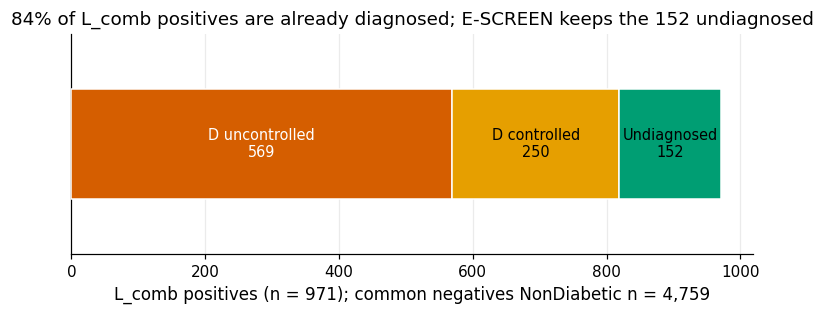

In [16]:
strata = L.strata_counts(d)
esc = d[d["in_escreen"] == 1]
esc_counts = {"n": len(esc), "positives": int(esc["y_escreen"].sum()), "negatives": int((esc["y_escreen"] == 0).sum()),
              "borderline_in_escreen": int(esc["borderline"].sum()),
              "borderline_positive": int(((esc["borderline"] == 1) & (esc["y_escreen"] == 1)).sum())}
print("3x3 evaluation strata:", strata)
print("E-SCREEN:", esc_counts)
assert strata == {"D_uncontrolled": 569, "D_controlled": 250, "Undiagnosed": 152, "NonDiabetic": 4759}
assert esc_counts["positives"] == 152 and esc_counts["borderline_positive"] == 36

fm = L.fasting_mask(d)
sl_rows = []
for col, desc, wcol in [("SL1", "L_A1c only", WT), ("SL2", "L_self only", WT), ("SL3", "borderline counted positive", WT),
                        ("SL4", "treatment-aware (A1c or treated self-report, DIQ070 universe)", WT),
                        ("SL5", "NCHS: self-report or A1c>=6.5 or FPG>=126, fasting subsample", C.WEIGHT_FASTING)]:
    w = S.weighted_prop(d.assign(_y=sl[col]), "_y", weight=wcol)
    sl_rows.append({"label": col, "definition": desc, "n": int(sl[col].notna().sum()), "positives": int(sl[col].sum()),
                    "prev_unweighted": sl[col].mean(), "weight": wcol, "w_prev": w["est"], "w_ci_low": w["ci_low"], "w_ci_high": w["ci_high"]})
sl_tab = pd.DataFrame(sl_rows)
print(sl_tab.round(3).to_string(index=False))
univ = L.diq070_universe(d)
pills_by_status = d[d["DIQ070"].eq(1)].groupby(d["DIQ010"].map({1: "diagnosed", 2: "no (told prediabetes)", 3: "borderline"})).size()
print("DIQ070 = 1 by DIQ010:", pills_by_status.to_dict(), f"; DIQ070 universe n = {int(univ.sum())}")
SLT = sl_tab.set_index("label")
assert SLT["positives"].tolist() == [721, 819, 1148, 886, int(SLT.loc["SL5", "positives"])]
assert pills_by_status.to_dict() == {"borderline": 44, "diagnosed": 592, "no (told prediabetes)": 41}
close(SLT.loc["SL5", "w_prev"], 0.158, 0.006, "SL5 vs NCHS DB516 15.8%")

freeze_path = C.GOVERNANCE_DIR / "label_freeze.md"
freeze_text = freeze_path.read_text(encoding="utf-8")
frozen = json.loads(freeze_text.split("```json")[1].split("```")[0])
computed = {"N": len(d), "L_comb": n_comb, "L_self": int(d["L_self"].sum()), "L_A1c": int(d["L_A1c"].sum()),
            "strata_3x3": strata, "escreen_positives": esc_counts["positives"], "escreen_negatives": esc_counts["negatives"],
            "escreen_borderline_positive": esc_counts["borderline_positive"],
            "SL_positives": {k: int(v) for k, v in SLT["positives"].items()}, "SL5_n": int(SLT.loc["SL5", "n"])}
assert frozen == computed, {k: (frozen.get(k), v) for k, v in computed.items() if frozen.get(k) != v}
freeze_sha = hashlib.sha256(freeze_path.read_bytes()).hexdigest()
print(f"label_freeze.md counts match the code; SHA-256 {freeze_sha[:16]}…")

fig, ax = plt.subplots(figsize=(8, 2.6))
cols = [plots.PALETTE[5], plots.PALETTE[0], plots.PALETTE[2]]
left = 0
for k, col in zip(L.POSITIVE_STRATA, cols):
    ax.barh(0, strata[k], left=left, height=0.5, color=col, edgecolor="white", zorder=3)
    ax.text(left + strata[k] / 2, 0, f"{k.replace('_', ' ')}\n{strata[k]}", ha="center", va="center", fontsize=9.5,
            color="white" if k == "D_uncontrolled" else "black", zorder=4)
    left += strata[k]
ax.set_yticks([])
ax.grid(axis="y", visible=False)
known = strata["D_uncontrolled"] + strata["D_controlled"]
ax.set(xlabel=f"L_comb positives (n = {n_comb}); common negatives NonDiabetic n = {strata['NonDiabetic']:,}", ylim=(-0.5, 0.5),
       title=f"{pct(known / n_comb, 0)} of L_comb positives are already diagnosed; E-SCREEN keeps the {strata['Undiagnosed']} undiagnosed")
plots.savefig(fig, "S5_label_strata", caption="Composition of the 971 L_comb positives by self-report and HbA1c; "
              "D_uncontrolled 569, D_controlled 250, Undiagnosed 152 (= E-SCREEN positives).")
plt.show()

sl_tab.to_csv(OUT / "sensitivity_labels.csv", index=False)
RES["freeze"] = {"target": "L_comb = (DIQ010 == 1) | (LBXGH >= 6.5)", "N": len(d), "gate": gate.set_index("criterion")["verdict"].to_dict(),
                 "gate_posthoc": True, "strata_3x3": strata, "escreen": esc_counts,
                 "sensitivity_labels": sl_tab.set_index("label")[["n", "positives", "prev_unweighted", "w_prev", "weight"]].to_dict("index"),
                 "known_dx_share_of_positives": strata["D_uncontrolled"] / n_comb + strata["D_controlled"] / n_comb,
                 "label_freeze_sha256": freeze_sha}
register("DR-S5-01", "target_freeze",
         "L2 gate C1-C4 passes (post-hoc); the union label is the least biased single target",
         "results/S5/l2_gate.csv; governance/label_freeze.md",
         f"L_comb {n_comb} positives ({pct(n_comb / len(d))}; weighted {pct(w_prev['est'])}); C1 15.7%/25.7% missed by single labels; "
         f"C3 Asian L_comb {int(race_pos.loc['NH Asian', 'L_comb'])}",
         "Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on N=5,730 (tag target-freeze); any change requires a register entry and reopening L2",
         "Freeze L_self (misses 152 undiagnosed); freeze L_A1c (misses 250 controlled); borderline positive (SL3, kept as sensitivity)",
         loop_ref="L2", check_note="Gate recomputed in §5.8; post-hoc nature stated")
register("DR-S5-09", "evaluation_population",
         "84% of L_comb positives are already diagnosed, so E-ALL measures recognition of known disease",
         "governance/label_freeze.md; figures/S5_label_strata.png",
         f"E-SCREEN: {esc_counts['n']} adults, {esc_counts['positives']} positives vs {esc_counts['negatives']} negatives; "
         f"borderline kept with {esc_counts['borderline_positive']} positive; 3x3 strata 569/250/152/4759",
         "E-SCREEN (DIQ010!=1, y = HbA1c>=6.5) is a co-primary evaluation population next to E-ALL; 3x3 label matrix (SL6) evaluated in S8 at specificity 0.80",
         "Evaluate on E-ALL only; train on E-SCREEN only (152 events too few)", loop_ref="L2")
register("DR-S5-10", "sensitivity_labels",
         "Label definition is a researcher degree of freedom; robustness needs pre-specified alternatives",
         "results/S5/sensitivity_labels.csv; governance/label_freeze.md",
         "SL1 721, SL2 819, SL3 1,148, SL4 886, SL5 " + f"{int(SLT.loc['SL5', 'positives'])}/{int(SLT.loc['SL5', 'n'])} (weighted {pct(SLT.loc['SL5', 'w_prev'])})",
         "Freeze SL1-SL7 as executable definitions (src/labels.py); SL4 uses only the DIQ070 universe and excludes pills of non-diagnosed respondents; S9 reports results under SL1-SL5, S8 runs SL6, S9 runs SL7",
         "Ad-hoc relabelling after seeing model results; DIQ070 pills as diabetes for all respondents (would count pills plausibly taken for prediabetes, e.g. metformin)")

**So what.** All four gate criteria pass, as a post-hoc judgement made after seeing the data: each single
instrument misses a material share of the union (15.7 % and 25.7 %), no admissible feature is part of the
target, every race group has at least 40 positives (NH Asian 50 under `L_comb`, exactly 40 under `L_A1c`, so
Asian results stay descriptive), and borderline coding is handled by SL3. **`L_comb` is frozen.** Of the 971
positives, 84 % are already diagnosed (569 uncontrolled, 250 controlled), so E-SCREEN (152 undiagnosed
positives vs 4,759 negatives) is co-primary, and §8.6 evaluates every training label on each 3×3 column. SL5
closely reproduces the published DB516 prevalence of 15.8 %, anchoring the label pipeline externally.

## 9 Hypothesis status and outputs

**Why.** Three entries of `governance/hypotheses.md` are checked in this section. All three were written after
the data had been analysed (`analysis_seen` / `descriptive_seen`), so "supported" here confirms a reproduced
description, not confirmatory evidence. The decision register (`governance/register/S5.csv`) and
`results/metrics_S5.json` are written at the end.

In [17]:
from statsmodels.stats.proportion import confint_proportions_2indep

ka, na_ = int(bmi_dm.loc["NH Asian", "bmi_lt25"]), int(bmi_dm.loc["NH Asian", "diabetics_with_bmi"])
kw, nw = int(bmi_dm.loc["NH White", "bmi_lt25"]), int(bmi_dm.loc["NH White", "diabetics_with_bmi"])
h4a_lo, h4a_hi = confint_proportions_2indep(ka, na_, kw, nw, method="newcomb", compare="diff")
h4a = ka / na_ - kw / nw
rd_bmi = risk_difference(d.assign(bmi_lt25=(d["BMXBMI"] < 25).astype(float).where(d["BMXBMI"].notna())), "bmi_lt25",
                         ((d["RIDRETH3"] == 6) & (d["L_comb"] == 1)).to_numpy(), ((d["RIDRETH3"] == 3) & (d["L_comb"] == 1)).to_numpy())
g_as, g_wh = RO.loc[("NH Asian", "WHtR − BMI (paired)")], RO.loc[("NH White", "WHtR − BMI (paired)")]
rd_un = RD.loc["uninsured - insured"]
hyp = pd.DataFrame([
    {"hyp_id": "H1a", "estimate": f"RD uninsured - insured {rd_un['rd_pp']:+.1f} pp ({rd_un['ci_low_pp']:.1f}, {rd_un['ci_high_pp']:.1f})",
     "rule": "lower CI bound > 0", "verdict": "supported" if rd_un["ci_low_pp"] > 0 else "inconclusive",
     "note": "uninsured share exploratory (KG width >= 0.30)"},
    {"hyp_id": "H4a", "estimate": f"BMI<25 among diabetics, Asian - White {100 * h4a:+.1f} pp (Newcombe {100 * h4a_lo:.1f}, {100 * h4a_hi:.1f}); "
                                  f"weighted {100 * rd_bmi['est']:+.1f} pp (JK {100 * rd_bmi['ci_low']:.1f}, {100 * rd_bmi['ci_high']:.1f})",
     "rule": "difference >= 20 pp with CI above 20 pp",
     "verdict": "supported" if h4a_lo >= 0.20 else ("inconclusive" if h4a >= 0.20 else "refuted"),
     "note": "47 Asian diabetics with BMI: exploratory"},
    {"hyp_id": "H4b", "estimate": f"WHtR - BMI gain Asian {g_as['auc']:+.3f} ({g_as['ci_low']:.3f}, {g_as['ci_high']:.3f}) vs "
                                  f"White {g_wh['auc']:+.3f} ({g_wh['ci_low']:.3f}, {g_wh['ci_high']:.3f}); difference CI "
                                  f"(person {gain_diff.quantile(.025):+.3f}, {gain_diff.quantile(.975):+.3f}; "
                                  f"PSU {np.quantile(psu_diff, .025):+.3f}, {np.quantile(psu_diff, .975):+.3f})",
     "rule": "Asian gain larger and CIs not fully overlapping",
     "verdict": "supported" if (g_as["auc"] > g_wh["auc"] and g_as["ci_low"] > g_wh["ci_low"] and np.quantile(psu_diff, .025) > 0) else "inconclusive",
     "note": "descriptive_seen; confirmatory test of the WHtR arm is P14 in S8"},
])
display(hyp)
assert hyp["verdict"].tolist() == ["supported", "supported", "supported"]
hyp.to_csv(OUT / "hypothesis_checks.csv", index=False)
RES["hypotheses"] = hyp.set_index("hyp_id").to_dict("index")
RES["undiagnosed_inequality"]["rd_df_sensitivity"] = rd_df.set_index("contrast").to_dict("index")
for r in REG:   # link register rows to the hypotheses they inform
    r["hyp_id"] = {"DR-S5-05": "H1a", "DR-S5-06": "H4a; H4b", "DR-S5-09": "H2c; H3"}.get(r["dr_id"], r["hyp_id"])

# prior_exposure of every hypothesis, read from the locked governance/hypotheses.md
_rows = [ln.split("|") for ln in (C.GOVERNANCE_DIR / "hypotheses.md").read_text(encoding="utf-8").splitlines()
         if ln.startswith("| H") and not ln.startswith("| hyp_id")]
prior = {r[1].strip(): r[9].strip() for r in _rows if len(r) > 10}
display(pd.Series(prior, name="prior_exposure").to_frame().T)
genuine = sorted(h for h, p in prior.items() if p == "none")
print("genuinely pre-registered (prior_exposure = none):", genuine)
assert {"H2b", "H2c", "H3"} <= set(genuine) and prior.get("H2a") == "analysis_seen"

,hyp_id,estimate,rule,verdict,note
0,H1a,"RD uninsured - insured +23.2 pp (6.2, 40.1)",lower CI bound > 0,supported,uninsured share exploratory (KG width >= 0.30)
1,H4a,"BMI<25 among diabetics, Asian - White +43.9 pp...",difference >= 20 pp with CI above 20 pp,supported,47 Asian diabetics with BMI: exploratory
2,H4b,"WHtR - BMI gain Asian +0.137 (0.093, 0.181) vs...",Asian gain larger and CIs not fully overlapping,supported,descriptive_seen; confirmatory test of the WHt...


,H1a,H1b,H2a,H2b,H2c,H3,H4a,H4b
prior_exposure,analysis_seen,analysis_seen,analysis_seen,none,none,none,analysis_seen,descriptive_seen


genuinely pre-registered (prior_exposure = none): ['H2b', 'H2c', 'H3']


**So what.** H1a (uninsured adults more often undiagnosed), H4a (BMI < 25 far more common among Asian
diabetics) and H4b (larger WHtR gain in Asian adults) are reproduced with intervals that satisfy their
pre-stated rules, with the caveats printed above. Because the hypotheses were written after seeing these data,
they are recorded as *supported (analysis_seen)*. The genuinely pre-registered tests (`prior_exposure = none`)
are H2b, H2c and H3 in §7–§8; H2a (leakage gate) is `analysis_seen` and the WHtR arm P14 is `descriptive_seen`.

In [18]:
reg_df = pd.DataFrame(REG).sort_values("dr_id").reset_index(drop=True)
reg_path = C.GOVERNANCE_DIR / "register" / "S5.csv"
reg_path.parent.mkdir(parents=True, exist_ok=True)
reg_df.to_csv(reg_path, index=False, lineterminator="\n")
R.save_section("S5", RES)
print(f"{len(reg_df)} register rows -> {reg_path.relative_to(C.ROOT).as_posix()}; results -> results/metrics_S5.json")
display(reg_df[["dr_id", "type", "decision"]])

10 register rows -> governance/register/S5.csv; results -> results/metrics_S5.json


,dr_id,type,decision
0,DR-S5-01,target_freeze,Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on N=5...
1,DR-S5-02,label_audit,Use the union L_comb as training target; repor...
2,DR-S5-03,label_bias,Reject L_A1c as the sole target; keep stratum ...
3,DR-S5-04,label_semantics,Frame E-SCREEN positives as 'not diagnosed des...
4,DR-S5-05,label_bias,Headline = risk difference with JK CI (df of t...
5,DR-S5-06,measurement_bias,"Pre-register P14 (WHtR replaces waist, BMI kep..."
6,DR-S5-07,representation,Descriptive population estimates use WTPH2YR w...
7,DR-S5-08,missingness,Keep complete-case cohort with WTPH2YR; report...
8,DR-S5-09,evaluation_population,"E-SCREEN (DIQ010!=1, y = HbA1c>=6.5) is a co-p..."
9,DR-S5-10,sensitivity_labels,Freeze SL1-SL7 as executable definitions (src/...
